# Agente de detección de riesgo de phishing en sitios web

Notebook del proyecto *Modelo de IA para evaluar el riesgo en sitios web y detección de posibles sitios web de phishing*. A continuacion se sigue la Tabla IV del paper, donde cada sección corresponde a un módulo del diseño.

## 0. Configuración

In [ ]:
%pip install -q python-whois tldextract shap

In [41]:
import os, sys, io, re, json, time, math, random, hashlib, socket, ipaddress, threading, warnings
from collections import Counter
from dataclasses import dataclass, field, asdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Optional
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.parse import urlparse, urljoin, parse_qsl, urlencode, urlunparse
import importlib.metadata as md

import numpy as np
import pandas as pd
import joblib, requests, shap, tldextract, whois
from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# parámetros
SEED = 42
SENTINEL = -1          # valor para las características que no se pudieron calcular
FAST_MODE = False       # True = prueba rápida de inicio correcto.

CFG = dict(
    n_per_class=10_000, tranco_top=100_000, max_per_domain=5, p_internal_link=0.7,
    workers=32, use_whois=True, equalize_missingness=True,
    test_size=0.20, n_folds=10, inner_folds=5,
    k_fractions=[0.6, 0.7, 0.8, 0.9], top_k_factors=3, background_size=50,
    thresholds=dict(bajo=0.30, alto=0.70),
    n_estimators=200,
    grid_xgb=dict(max_depth=[4, 6], learning_rate=[0.05, 0.1], n_estimators=[200, 400]),
    grid_rf=dict(max_depth=[None, 20], n_estimators=[200, 400], min_samples_leaf=[1, 3]),
    grid_meta=dict(n_estimators=[30, 50, 100], max_depth=[1, 2, 3], learning_rate=[0.1]),
    shap_global_rows=200,
)
if FAST_MODE:
    CFG.update(
        n_per_class=300, tranco_top=20_000, workers=16, n_folds=3, inner_folds=3,
        k_fractions=[0.6, 0.8], n_estimators=60, shap_global_rows=50,
        grid_xgb=dict(max_depth=[4], learning_rate=[0.1], n_estimators=[60]),
        grid_rf=dict(max_depth=[None], n_estimators=[60], min_samples_leaf=[1]),
        grid_meta=dict(n_estimators=[30, 50], max_depth=[2], learning_rate=[0.1]),
    )
    print("*** MODO RÁPIDO ACTIVO: los resultados no sirven para el paper. ***")

# rutas (Drive)
RUN = "fast" if FAST_MODE else "full"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/phishing_agent")
except ImportError:                      # fuera de Colab (pruebas locales)
    BASE = Path("./phishing_agent")
DATA_DIR, ART_DIR, RES_DIR = (BASE / d / RUN for d in ("dataset", "artefactos", "resultados"))
for d in (DATA_DIR, ART_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED)

# entorno (para la Tabla III)
LIBS = ("scikit-learn", "xgboost", "lightgbm", "shap", "joblib", "requests",
        "beautifulsoup4", "python-whois", "tldextract", "pandas", "numpy")
VERSIONS = {p: md.version(p) for p in LIBS}
entorno = {"python": sys.version.split()[0], **VERSIONS}
try:
    import psutil
    entorno.update(cpu=psutil.cpu_count(), ram_gb=round(psutil.virtual_memory().total / 1e9, 1),
                   disco_libre_gb=round(psutil.disk_usage("/").free / 1e9, 1))
except ImportError:
    pass
print(json.dumps(entorno, indent=2))
(BASE / "requirements.txt").write_text("\n".join(f"{k}=={v}" for k, v in VERSIONS.items()))
(RES_DIR / "entorno.json").write_text(json.dumps(entorno, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "python": "3.13.16",
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "lightgbm": "4.6.0",
  "shap": "0.54.1",
  "joblib": "1.6.0",
  "requests": "2.32.4",
  "beautifulsoup4": "4.13.5",
  "python-whois": "0.9.6",
  "tldextract": "5.4.0",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "cpu": 2,
  "ram_gb": 13.6,
  "disco_libre_gb": 93.6
}


341

## 1. Dataset (módulo del diseño: Entrenamiento)

Se arma una lista de URLs crudas: phishing desde feeds públicos y legítimas desde la lista Tranco. Aquí solo se *recolectan, deduplican y fechan* las URLs. La descarga del HTML y el cálculo de características se hacen en las secciones 2 y 3.

- **Phishing:** Phishing.Database (lista de enlaces activos en GitHub) y OpenPhish.
- **Legítimas:** Tranco. Si falla la descarga, baja el CSV a mano y súbelo a `dataset/tranco.csv` en Drive (columnas `rank,domain`).

In [42]:
EXT = tldextract.TLDExtract(suffix_list_urls=())      # usa la lista de sufijos incluida (sin red)

def registered_domain(url_or_host):
    s = url_or_host if "://" in url_or_host else "http://" + url_or_host
    host = (urlparse(s).hostname or "").lower()
    r = EXT(host)
    d = getattr(r, "top_domain_under_public_suffix", "") or r.registered_domain
    return d or host

def normalize_url(url):
    """http/https, sin fragmento, esquema y host en minúsculas. None si no sirve."""
    try:
        p = urlparse(url.strip())
        if p.scheme.lower() not in ("http", "https") or not p.hostname:
            return None
        return urlunparse((p.scheme.lower(), p.netloc.lower(), p.path or "/", p.params, p.query, ""))
    except ValueError:
        return None

PHISH_SOURCES = {
    "phishing_database": "https://raw.githubusercontent.com/mitchellkrogza/Phishing.Database/master/phishing-links-ACTIVE.txt",
    "openphish": "https://openphish.com/feed.txt",
}
PHISHTANK_APP_KEY = os.environ.get("PHISHTANK_APP_KEY", "")
UA = {"User-Agent": "Mozilla/5.0 (PhishRiskAgent/0.1; investigacion academica)"}

def _download_text(url, timeout=120):
    r = requests.get(url, timeout=timeout, headers=UA)
    r.raise_for_status()
    return r.text

def load_phishing_urls():
    out = []
    for name, src in PHISH_SOURCES.items():
        try:
            lines = [l.strip() for l in _download_text(src).splitlines() if l.strip()]
            out += [(u, name) for u in lines]
            print(f"{name}: {len(lines)} líneas")
        except Exception as e:
            print(f"{name}: no disponible ({type(e).__name__})")
    if PHISHTANK_APP_KEY:
        try:
            df = pd.read_csv(io.StringIO(_download_text(
                f"https://data.phishtank.com/data/{PHISHTANK_APP_KEY}/online-valid.csv")))
            out += [(u, "phishtank") for u in df["url"].dropna()]
            print(f"phishtank: {len(df)} filas")
        except Exception as e:
            print(f"phishtank: no disponible ({type(e).__name__})")
    return out

def load_tranco_domains(top):
    local = DATA_DIR.parent / "tranco.csv"
    if local.exists():
        df = pd.read_csv(local, header=None, names=["rank", "domain"])
    else:
        raw = requests.get("https://tranco-list.eu/top-1m.csv.zip", timeout=120, headers=UA)
        raw.raise_for_status()
        df = pd.read_csv(io.BytesIO(raw.content), compression="zip", header=None, names=["rank", "domain"])
    return df.sort_values("rank").head(top)["domain"].astype(str).tolist()

def build_dataset(n_per_class=None, seed=SEED):
    """Recolecta, deduplica, limita URLs por dominio y registra la fecha de captura."""
    n = n_per_class or CFG["n_per_class"]
    rng = random.Random(seed)
    stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")

    raw = load_phishing_urls()
    rng.shuffle(raw)                       # las listas vienen ordenadas: hay que muestrear al azar
    seen, per_dom, phish = set(), {}, []
    for u, src in raw:
        nu = normalize_url(u)
        if not nu or nu in seen:
            continue
        d = registered_domain(nu)
        if per_dom.get(d, 0) >= CFG["max_per_domain"]:
            continue
        seen.add(nu); per_dom[d] = per_dom.get(d, 0) + 1
        phish.append(dict(url=nu, label=1, domain=d, source=src, captured_at=stamp))
        if len(phish) >= n:
            break

    doms = load_tranco_domains(CFG["tranco_top"])
    rng.shuffle(doms)
    legit = [dict(url=f"https://{d}/", label=0, domain=registered_domain(d),
                  source="tranco", captured_at=stamp) for d in doms[:n]]

    df = pd.concat([pd.DataFrame(phish), pd.DataFrame(legit)], ignore_index=True)
    print(df.groupby("label").size().rename({0: "legitimas", 1: "phishing"}))
    return df

df = build_dataset()
display(df.head(10))
print("\nTamaño del dataset:", df.shape)
print("\nURLs por clase:")
print(df["label"].value_counts().rename(index={
    0: "Legítimas",
    1: "Phishing"
}))

phishing_database: 789054 líneas
openphish: 300 líneas
label
legitimas    10000
phishing     10000
dtype: int64


,url,label,domain,source,captured_at
0,http://civilcontractorsinmumbai.in/signonv2scr...,1,civilcontractorsinmumbai.in,phishing_database,2026-10-22T21:32:28+00:00
1,http://newsflash.cf/yahoo_logoooo/mint/y,1,newsflash.cf,phishing_database,2026-10-22T21:32:28+00:00
2,https://discordjs.sanbaideng.workers.dev/,1,workers.dev,phishing_database,2026-10-22T21:32:28+00:00
3,https://purple-efax-0dca.info1198.workers.dev/...,1,workers.dev,phishing_database,2026-10-22T21:32:28+00:00
4,https://www.garena-freefire-coom.duckdns.org/,1,duckdns.org,phishing_database,2026-10-22T21:32:28+00:00
5,https://www.stornoacquisto.com/,1,stornoacquisto.com,phishing_database,2026-10-22T21:32:28+00:00
6,https://www.arnzon.account-support.top/esibgglg,1,account-support.top,phishing_database,2026-10-22T21:32:28+00:00
7,https://www.ndnmag.fr/en/80a85e5aa02ac554efae4...,1,ndnmag.fr,phishing_database,2026-10-22T21:32:28+00:00
8,https://g.kaiche.tk/,1,kaiche.tk,phishing_database,2026-10-22T21:32:28+00:00
9,https://www.m.faceebok.com-listing-id535002358...,1,sherese1538.com,phishing_database,2026-10-22T21:32:28+00:00



Tamaño del dataset: (20000, 5)

URLs por clase:
label
Phishing     10000
Legítimas    10000
Name: count, dtype: int64


## 2. Adquisición (módulo del diseño: `URLFetcher`)

Es el único componente que toca la red y el contenido no confiable (ver Tabla II del paper): no ejecuta JavaScript, valida el destino en cada redirección, y limita tiempo, tamaño y redirecciones.

In [43]:
class URLFetcher:
    def __init__(self, timeout=(3, 6), max_bytes=2_000_000, max_redirects=5,
                 max_seconds=15, whois_timeout=5, use_whois=True):
        self.timeout, self.max_bytes = timeout, max_bytes
        self.max_redirects, self.max_seconds = max_redirects, max_seconds
        self.whois_timeout, self.use_whois = whois_timeout, use_whois
        self._whois_cache, self._lock = {}, threading.Lock()

    def is_safe_target(self, url):
        p = urlparse(url)
        if p.scheme not in ("http", "https") or not p.hostname:
            return False
        try:
            infos = socket.getaddrinfo(p.hostname, p.port or 443)
        except (socket.gaierror, UnicodeError):
            return False
        return all(ipaddress.ip_address(i[4][0]).is_global for i in infos)

    def _download(self, url):
      ua = {"User-Agent": "Mozilla/5.0 (PhishRiskAgent/0.1)"}
      limite = time.monotonic() + self.max_seconds

      try:
          for _ in range(self.max_redirects + 1):
              if not self.is_safe_target(url):
                  return {
                      "final_url": url,
                      "html": None,
                      "error": "destino no permitido"
                  }

              r = requests.get(
                  url,
                  headers=ua,
                  timeout=self.timeout,
                  stream=True,
                  allow_redirects=False
              )

              if r.is_redirect:
                  url = urljoin(url, r.headers.get("Location", ""))
                  r.close()
                  continue

              if "html" not in r.headers.get("Content-Type", "").lower():
                  r.close()
                  return {
                      "final_url": url,
                      "html": None,
                      "error": "no es HTML"
                  }

              datos = bytearray()

              for trozo in r.iter_content(8192):
                  if time.monotonic() > limite:
                      break

                  if len(datos) + len(trozo) > self.max_bytes:
                      datos.extend(trozo[:self.max_bytes - len(datos)])
                      break

                  datos.extend(trozo)

              encoding = r.encoding or "utf-8"
              r.close()

              try:
                  html = bytes(datos).decode(encoding, errors="replace")
              except LookupError:
                  # Si Python no reconoce la codificación indicada por el servidor
                  try:
                      html = bytes(datos).decode("cp874", errors="replace")
                  except (LookupError, UnicodeError):
                      html = bytes(datos).decode("utf-8", errors="replace")

              return {
                  "final_url": url,
                  "html": html,
                  "error": None
              }

          return {
              "final_url": url,
              "html": None,
              "error": "demasiadas redirecciones"
          }

      except requests.RequestException as e:
          return {
              "final_url": url,
              "html": None,
              "error": type(e).__name__
          }

    def domain_age_days(self, domain):
        with self._lock:
            if domain in self._whois_cache:
                return self._whois_cache[domain]
        try:
            ipaddress.ip_address(domain)          # una IP no tiene WHOIS por nombre
            age = SENTINEL
        except ValueError:
            try:
                c = whois.whois(domain, timeout=self.whois_timeout).creation_date
                c = min(c) if isinstance(c, list) else c
                if c.tzinfo is None:
                    c = c.replace(tzinfo=timezone.utc)
                age = (datetime.now(timezone.utc) - c).days
            except Exception:
                age = SENTINEL
        with self._lock:
            self._whois_cache[domain] = age
        return age

    def fetch(self, url):
        page = self._download(url)
        page["domain_age_days"] = (self.domain_age_days(registered_domain(page["final_url"]))
                                   if self.use_whois else SENTINEL)
        return page



def expand_legit_urls(df, fetcher, p_internal=None, workers=None, seed=SEED):
    """Expande una parte de las URLs legítimas usando enlaces internos."""

    p = CFG["p_internal_link"] if p_internal is None else p_internal

    def internal_link(url):
        rng = random.Random(f"{seed}-{url}")

        if rng.random() > p:
            return url

        page = fetcher._download(url)

        if not page["html"]:
            return url

        base = page["final_url"]
        dom = registered_domain(base)
        cands = set()

        try:
            soup = BeautifulSoup(page["html"], "html5lib")
            for a in soup.find_all("a", href=True):
                try:
                    link = normalize_url(urljoin(base, a["href"]))
                    if (
                        link
                        and registered_domain(link) == dom
                        and urlparse(link).path not in ("", "/")
                    ):
                        cands.add(link)
                except (ValueError, TypeError):
                    continue
        except Exception:
            return url
        return rng.choice(sorted(cands)) if cands else url

    df = df.copy()
    idx = df.index[df["label"] == 0]

    with ThreadPoolExecutor(workers or CFG["workers"]) as ex:
        nuevos = list(
            tqdm(
                ex.map(internal_link, df.loc[idx, "url"]),
                total=len(idx)
            )
        )

    df.loc[idx, "url"] = nuevos
    return df.drop_duplicates("url").reset_index(drop=True)

## 3. Extracción (módulo del diseño: `FeatureExtractor`)

El mismo código calcula las características al construir el dataset y al analizar una URL nueva. Lo que no se puede calcular (HTML o WHOIS no disponibles) queda con el valor centinela `-1`.

In [44]:
KEYWORDS = ("login", "signin", "verify", "secure", "account", "update", "bank",
            "confirm", "password", "paypal", "webscr", "wallet", "billing")
SHORTENERS = {"bit.ly", "tinyurl.com", "t.co", "goo.gl", "ow.ly", "is.gd", "buff.ly",
              "rebrand.ly", "cutt.ly", "tiny.cc", "shorturl.at"}

def shannon_entropy(s):
    if not s:
        return 0.0
    c, n = Counter(s), len(s)
    return -sum(v / n * math.log2(v / n) for v in c.values())


class FeatureExtractor:
    lexical_features = ["url_length", "hostname_length", "path_length", "query_length",
                        "num_dots", "num_hyphens", "digit_ratio", "num_subdomains", "has_ip",
                        "has_at", "uses_https", "has_port", "num_path_slashes", "num_params",
                        "num_special_chars", "keyword_count", "host_entropy", "is_shortener",
                        "has_punycode"]
    domain_features = ["domain_age_days"]
    html_features = ["has_login_form", "num_forms", "num_inputs", "num_scripts",
                     "num_external_scripts", "num_links", "external_links_ratio",
                     "has_iframe", "external_form_action"]

    def __init__(self, sentinel=SENTINEL):
        self.sentinel = sentinel

    @property
    def feature_names(self):
        return self.lexical_features + self.domain_features + self.html_features

    def lexical(self, url):
        p = urlparse(url)
        host = (p.hostname or "").lower()
        low = url.lower()
        sub = [s for s in EXT(host).subdomain.split(".") if s]
        try:
            ipaddress.ip_address(host); is_ip = 1
        except ValueError:
            is_ip = 0
        try:
            port = p.port
        except ValueError:
            port = None
        return {
            "url_length": len(url), "hostname_length": len(host),
            "path_length": len(p.path), "query_length": len(p.query),
            "num_dots": host.count("."), "num_hyphens": host.count("-"),
            "digit_ratio": sum(ch.isdigit() for ch in url) / max(len(url), 1),
            "num_subdomains": len(sub), "has_ip": is_ip, "has_at": int("@" in url),
            "uses_https": int(p.scheme == "https"),
            "has_port": int(port not in (None, 80, 443)),
            "num_path_slashes": p.path.count("/"),
            "num_params": len(parse_qsl(p.query, keep_blank_values=True)),
            "num_special_chars": sum(url.count(c) for c in "?=&%_~"),
            "keyword_count": sum(low.count(k) for k in KEYWORDS),
            "host_entropy": round(shannon_entropy(host), 4),
            "is_shortener": int(registered_domain(host) in SHORTENERS),
            "has_punycode": int("xn--" in host),
        }

    def html_part(self, url, page):
        if not page or not page.get("html"):
            return {k: self.sentinel for k in self.html_features}
        base = page.get("final_url") or url
        site = registered_domain(base)
        soup = BeautifulSoup(page["html"], "html5lib")

        def is_external(link):
            full = urljoin(base, link)
            return urlparse(full).scheme in ("http", "https") and registered_domain(full) != site

        links = [a["href"] for a in soup.find_all("a", href=True)
                 if not a["href"].lower().startswith(("javascript:", "mailto:", "tel:", "#"))]
        forms = soup.find_all("form")
        n_ext_links = sum(is_external(l) for l in links)
        return {
            "has_login_form": int(soup.find("input", attrs={"type": re.compile("^password$", re.I)}) is not None),
            "num_forms": len(forms), "num_inputs": len(soup.find_all("input")),
            "num_scripts": len(soup.find_all("script")),
            "num_external_scripts": sum(is_external(s["src"]) for s in soup.find_all("script", src=True)),
            "num_links": len(links),
            "external_links_ratio": n_ext_links / len(links) if links else 0.0,
            "has_iframe": int(soup.find("iframe") is not None),
            "external_form_action": int(any(f.get("action") and is_external(f["action"]) for f in forms)),
        }

    def extract(self, url, page=None):
        feats = self.lexical(url)
        feats["domain_age_days"] = (page or {}).get("domain_age_days", self.sentinel)
        feats.update(self.html_part(url, page))
        return feats


META_COLS = ["url", "label", "domain", "source", "captured_at", "final_url", "fetch_error"]

def _flush(rows, path):
    if rows:
        pd.DataFrame(rows).to_csv(path, mode="a", header=not path.exists(), index=False)

def compute_features_df(urls_df, fetcher, extractor, workers=None, ckpt=None, flush_every=500):
    """Descarga y extrae características. Guarda el avance y se reanuda si se corta la sesión."""
    ckpt = ckpt or DATA_DIR / "features.csv"
    done = set(pd.read_csv(ckpt, usecols=["url"])["url"]) if ckpt.exists() else set()
    todo = urls_df[~urls_df["url"].isin(done)].to_dict("records")
    print(f"ya procesadas: {len(done)} | por procesar: {len(todo)}")

    def work(row):
        try:
            page = fetcher.fetch(row["url"])
            feats = extractor.extract(row["url"], page)
            return {**row, "final_url": page["final_url"], "fetch_error": page["error"] or "", **feats}
        except Exception as e:
          return {
              **row,
              "final_url": row["url"],
              "fetch_error": f"{type(e).__name__}: {e}",
              **extractor.lexical(row["url"]),
              "domain_age_days": SENTINEL,
              **{k: SENTINEL for k in extractor.html_features}
          }

    buf, fallos = [], 0
    with ThreadPoolExecutor(workers or CFG["workers"]) as ex:
        futs = [ex.submit(work, r) for r in todo]
        for f in tqdm(as_completed(futs), total=len(futs)):
            r = f.result()
            if r is None:
                fallos += 1
                continue
            buf.append(r)
            if len(buf) >= flush_every:
                _flush(buf, ckpt); buf = []
    _flush(buf, ckpt)
    if fallos:
        print(f"filas con error inesperado (omitidas): {fallos}")
    df = pd.read_csv(ckpt)
    df["fetch_error"] = df["fetch_error"].fillna("")
    return df


def diagnostico_faltantes(df):
    """Proporción de valores faltantes por clase. Si difiere mucho entre clases, el modelo
    puede aprender 'sin HTML = phishing' (sesgo de disponibilidad), no una señal real."""
    out = pd.DataFrame({
        "html_faltante": (df["has_login_form"] == SENTINEL).groupby(df["label"]).mean(),
        "whois_faltante": (df["domain_age_days"] == SENTINEL).groupby(df["label"]).mean(),
    })
    return out.rename(index={0: "legitimo", 1: "phishing"}).round(3)


def equalize_missingness(df, seed=SEED):
    """Enmascara al azar HTML/WHOIS en la clase con menos faltantes hasta igualar las tasas.
    Es independiente de las características, así que no introduce fuga de información."""
    rng = np.random.default_rng(seed)
    df = df.copy()
    grupos = {"html": FeatureExtractor.html_features, "whois": FeatureExtractor.domain_features}
    for cols in grupos.values():
        miss = df[cols[0]] == SENTINEL
        tasa = miss.groupby(df["label"]).mean()
        menor = int(tasa.idxmin()); mayor = int(tasa.idxmax())
        if tasa[mayor] - tasa[menor] <= 1e-9:
            continue
        q = (tasa[mayor] - tasa[menor]) / (1 - tasa[menor])
        idx = df.index[(df["label"] == menor) & (~miss)]
        elegidos = idx[rng.random(len(idx)) < q]
        df.loc[elegidos, cols] = SENTINEL
    return df

### 3b. Construir el dataset de características

Recolecta las URLs, completa las legítimas con rutas internas, descarga y calcula las características. Es la celda lenta; el avance queda en Drive.

In [45]:
fetcher = URLFetcher(use_whois=CFG["use_whois"])
extractor = FeatureExtractor()

urls_path, flag = DATA_DIR / "urls.csv", DATA_DIR / "urls_expandido.flag"
if not urls_path.exists():
    urls_df = build_dataset()
    urls_df.to_csv(urls_path, index=False)
if not flag.exists():                       # se hace una sola vez
    urls_df = expand_legit_urls(pd.read_csv(urls_path), fetcher)
    urls_df.to_csv(urls_path, index=False)
    flag.touch()
urls_df = pd.read_csv(urls_path)

feat_df = compute_features_df(urls_df, fetcher, extractor)

print("\nFaltantes por clase (antes de igualar):")
faltantes = diagnostico_faltantes(feat_df)
print(faltantes)
faltantes.to_csv(RES_DIR / "faltantes.csv")

model_df = equalize_missingness(feat_df) if CFG["equalize_missingness"] else feat_df
if CFG["equalize_missingness"]:
    print("\nFaltantes por clase (después de igualar):")
    print(diagnostico_faltantes(model_df))

FEATURES = extractor.feature_names
X = model_df[FEATURES].reset_index(drop=True)
y = model_df["label"].to_numpy()
groups = model_df["domain"].to_numpy()
print(f"\nX: {X.shape} | phishing: {int(y.sum())} | legítimas: {int((1 - y).sum())} | dominios: {len(set(groups))}")

print("\nPromedio de cada característica por clase (revisa que no haya diferencias artificiales):")
print(model_df.groupby("label")[FEATURES].mean().T.rename(columns={0: "legitimo", 1: "phishing"}).round(3))

ya procesadas: 0 | por procesar: 19989


ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno 111] Connection refused
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known


  0%|          | 0/19989 [00:00<?, ?it/s]

ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno 111] Connection refused
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out
ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out
ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out
ERROR:whois.whois


Faltantes por clase (antes de igualar):
          html_faltante  whois_faltante
label                                  
legitimo          0.301           0.162
phishing          0.792           0.640

Faltantes por clase (después de igualar):
          html_faltante  whois_faltante
label                                  
legitimo          0.797           0.635
phishing          0.792           0.640

X: (19989, 29) | phishing: 10000 | legítimas: 9989 | dominios: 18058

Promedio de cada característica por clase (revisa que no haya diferencias artificiales):
label                 legitimo  phishing
url_length              33.337    81.995
hostname_length         13.383    21.371
path_length             10.619    30.373
query_length             1.264    22.238
num_dots                 1.301     1.702
num_hyphens              0.087     0.429
digit_ratio              0.016     0.094
num_subdomains           0.205     0.574
has_ip                   0.000     0.018
has_at                   0

## 4. Selección (módulo del diseño: `FeatureSelector`)

Importancia promedio de XGBoost, LightGBM y Random Forest. Cada vector se normaliza antes de promediar porque LightGBM entrega conteos de divisiones, no valores que sumen 1.

In [46]:
class FeatureSelector:
    def __init__(self, k_fraction=0.8, seed=SEED, n_estimators=None):
        self.k_fraction, self.seed = k_fraction, seed
        self.n_estimators = n_estimators or CFG["n_estimators"]
        self.importances, self.selected = {}, []

    def fit(self, X, y):
        n = self.n_estimators
        modelos = [XGBClassifier(n_estimators=n, eval_metric="logloss", random_state=self.seed),
                   LGBMClassifier(n_estimators=n, random_state=self.seed, verbose=-1),
                   RandomForestClassifier(n_estimators=n, random_state=self.seed, n_jobs=-1)]
        imps = []
        for m in modelos:
            m.fit(X, y)
            v = np.asarray(m.feature_importances_, dtype=float)
            imps.append(v / v.sum())
        prom = pd.Series(np.mean(imps, axis=0), index=X.columns).sort_values(ascending=False)
        self.importances = prom.to_dict()
        return self.set_k(self.k_fraction)

    def set_k(self, k_fraction):
        self.k_fraction = k_fraction
        k = max(1, round(k_fraction * len(self.importances)))
        self.selected = list(self.importances)[:k]
        return self

    def transform(self, X):
        return X[self.selected]

    @classmethod
    def from_selected(cls, selected):
        obj = cls()
        obj.selected = list(selected)
        obj.importances = {c: float("nan") for c in selected}
        return obj

## 5. Modelo y validación (módulo del diseño: `StackingModel`)

Primero se aparta un **conjunto de prueba final (20 % de los dominios)** que no se toca hasta el final. Sobre el 80 % restante se ajustan los hiperparámetros con búsqueda en grilla, se hace la validación cruzada de 10 particiones agrupada por dominio y se elige K. Las particiones internas del apilamiento también se agrupan por dominio, para que las predicciones fuera de muestra con que se entrena el meta-clasificador no vean el mismo dominio dos veces.

In [47]:
def metrics(y_true, p, thr=0.5):
    p = np.asarray(p)
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred, zero_division=0),
                f1=f1_score(y_true, pred, zero_division=0),
                fpr=fp / max(fp + tn, 1),
                auc=roc_auc_score(y_true, p))

def default_params():
    n = CFG["n_estimators"]
    return dict(
        xgb=dict(n_estimators=n, max_depth=6, learning_rate=0.1, eval_metric="logloss", random_state=SEED),
        rf=dict(n_estimators=n, n_jobs=-1, random_state=SEED),
        meta=dict(n_estimators=50, max_depth=2, learning_rate=0.1, eval_metric="logloss", random_state=SEED),
    )


class StackingModel:
    def __init__(self, params=None, inner_folds=None):
        self.params = params or default_params()
        self.inner_folds = inner_folds or CFG["inner_folds"]
        self.base_xgb = XGBClassifier(**self.params["xgb"])
        self.base_rf = RandomForestClassifier(**self.params["rf"])
        self.meta = XGBClassifier(**self.params["meta"])
        self.model = None

    def fit(self, X, y, groups=None):
        cv = (list(GroupKFold(n_splits=self.inner_folds).split(X, y, groups))
              if groups is not None else self.inner_folds)
        self.model = StackingClassifier(
            estimators=[("xgb", self.base_xgb), ("rf", self.base_rf)],
            final_estimator=self.meta, stack_method="predict_proba", cv=cv)
        self.model.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

    @classmethod
    def from_fitted(cls, sk_model):
        obj = cls.__new__(cls)
        obj.model = sk_model
        return obj


def tune_hyperparameters(X, y, groups):
    """Búsqueda en grilla (validación agrupada por dominio) solo sobre el conjunto de entrenamiento."""
    params, cv = default_params(), GroupKFold(n_splits=3)
    gx = GridSearchCV(XGBClassifier(**params["xgb"]), CFG["grid_xgb"], scoring="f1", cv=cv, n_jobs=1)
    gx.fit(X, y, groups=groups)
    params["xgb"].update(gx.best_params_)
    gr = GridSearchCV(RandomForestClassifier(**params["rf"]), CFG["grid_rf"], scoring="f1", cv=cv, n_jobs=1)
    gr.fit(X, y, groups=groups)
    params["rf"].update(gr.best_params_)
    # el meta-clasificador se ajusta sobre predicciones fuera de muestra de los modelos base
    oof = np.column_stack([
        cross_val_predict(m, X, y, groups=groups, cv=GroupKFold(CFG["inner_folds"]),
                          method="predict_proba")[:, 1]
        for m in (XGBClassifier(**params["xgb"]), RandomForestClassifier(**params["rf"]))])
    gm = GridSearchCV(XGBClassifier(**params["meta"]), CFG["grid_meta"], scoring="f1", cv=cv, n_jobs=1)
    gm.fit(oof, y, groups=groups)
    params["meta"].update(gm.best_params_)
    print("mejores hiperparámetros:", {k: gx.best_params_ if k == "xgb" else gr.best_params_ if k == "rf" else gm.best_params_
                                       for k in ("xgb", "rf", "meta")})
    return params


def fit_models(Xtr, ytr, gtr, params):
    return {"stacking": StackingModel(params).fit(Xtr, ytr, gtr),
            "xgboost": XGBClassifier(**params["xgb"]).fit(Xtr, ytr),
            "random_forest": RandomForestClassifier(**params["rf"]).fit(Xtr, ytr)}

def predict_all(models, Xte):
    return {"stacking": models["stacking"].predict_proba(Xte),
            "xgboost": models["xgboost"].predict_proba(Xte)[:, 1],
            "random_forest": models["random_forest"].predict_proba(Xte)[:, 1]}


def cross_validate_all(X, y, groups, params, k_fractions, n_folds):
    """Validación cruzada agrupada por dominio. La selección de variables se calcula
    solo con la partición de entrenamiento de cada iteración."""
    rows = []
    for fold, (tr, te) in enumerate(tqdm(list(GroupKFold(n_splits=n_folds).split(X, y, groups)), desc="folds")):
        sel = FeatureSelector(k_fraction=1.0).fit(X.iloc[tr], y[tr])
        for kf in k_fractions:
            sel.set_k(kf)
            Xtr, Xte = sel.transform(X.iloc[tr]), sel.transform(X.iloc[te])
            preds = predict_all(fit_models(Xtr, y[tr], groups[tr], params), Xte)
            for name, p in preds.items():
                rows.append(dict(fold=fold, k=kf, n_features=len(sel.selected), model=name, **metrics(y[te], p)))
    return pd.DataFrame(rows)

def summarize_cv(res):
    cols = ["accuracy", "precision", "recall", "f1", "fpr", "auc"]
    agg = res.groupby(["model", "k"]).agg(n_features=("n_features", "first"),
                                          **{c: (c, "mean") for c in cols}, f1_std=("f1", "std"))
    return agg.round(4)

def choose_k_fraction(res, tol=0.002):
    """Menor K cuya F1 media del stacking queda a menos de `tol` de la mejor (deja de mejorar)."""
    s = res[res["model"] == "stacking"].groupby("k")["f1"].mean()
    return float(s[s >= s.max() - tol].index.min())

### 5b. Experimento

Esta celda realiza la validación cruzada de los modelos de clasificación para evaluar su capacidad de detectar sitios web de phishing. Para ello, divide los datos en 10 particiones agrupadas por dominio, selecciona diferentes proporciones de características (60 %, 70 %, 80 % y 90 %) y entrena los modelos para comparar su rendimiento mediante métricas como precisión, recall, F1 y AUC. Los resultados permiten identificar la configuración con mejor desempeño para las siguientes etapas de evaluación.

In [48]:
t0 = time.perf_counter()
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=CFG["test_size"], random_state=SEED).split(X, y, groups))
print(f"entrenamiento: {len(tr)} filas | prueba final: {len(te)} filas")

# 1) hiperparámetros (solo con el entrenamiento)
params = tune_hyperparameters(X.iloc[tr], y[tr], groups[tr])

# 2) validación cruzada agrupada por dominio y elección de K
cv_res = cross_validate_all(X.iloc[tr].reset_index(drop=True), y[tr], groups[tr], params,
                            CFG["k_fractions"], CFG["n_folds"])
cv_summary = summarize_cv(cv_res)
print(cv_summary)
K_BEST = choose_k_fraction(cv_res)
print("\nK elegido (fracción de variables):", K_BEST)
cv_res.to_csv(RES_DIR / "cv_folds.csv", index=False)
cv_summary.to_csv(RES_DIR / "cv_resumen.csv")

# 3) evaluación final, una sola vez, en el 20 % apartado
sel_ho = FeatureSelector(k_fraction=K_BEST).fit(X.iloc[tr], y[tr])
models_ho = fit_models(sel_ho.transform(X.iloc[tr]), y[tr], groups[tr], params)
preds_ho = predict_all(models_ho, sel_ho.transform(X.iloc[te]))
holdout = pd.DataFrame({name: metrics(y[te], p) for name, p in preds_ho.items()}).T.round(4)
print("\nPrueba final (20 % apartado):")
print(holdout)
holdout.to_csv(RES_DIR / "holdout.csv")
pd.Series(sel_ho.importances).rename("importancia").to_csv(RES_DIR / "importancias.csv")
print("\nvariables elegidas:", sel_ho.selected)

# 4) modelo final: se reentrena con todos los datos, como indica el paper
sel_final = FeatureSelector(k_fraction=K_BEST).fit(X, y)
stack_final = StackingModel(params).fit(sel_final.transform(X), y, groups)
print(f"\ntiempo total del experimento: {(time.perf_counter() - t0) / 60:.1f} min")

entrenamiento: 15966 filas | prueba final: 4023 filas
mejores hiperparámetros: {'xgb': {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 400}, 'rf': {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200}, 'meta': {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 30}}


folds:   0%|          | 0/10 [00:00<?, ?it/s]

                   n_features  accuracy  precision  recall      f1     fpr  \
model         k                                                              
random_forest 0.6          17    0.9058     0.9152  0.8944  0.9047  0.0829   
              0.7          20    0.9061     0.9157  0.8944  0.9049  0.0824   
              0.8          23    0.9074     0.9174  0.8953  0.9062  0.0807   
              0.9          26    0.9069     0.9163  0.8957  0.9058  0.0819   
stacking      0.6          17    0.9099     0.9249  0.8923  0.9083  0.0725   
              0.7          20    0.9096     0.9232  0.8936  0.9081  0.0743   
              0.8          23    0.9111     0.9251  0.8945  0.9095  0.0724   
              0.9          26    0.9104     0.9263  0.8917  0.9086  0.0710   
xgboost       0.6          17    0.9090     0.9269  0.8880  0.9070  0.0700   
              0.7          20    0.9094     0.9282  0.8873  0.9073  0.0686   
              0.8          23    0.9102     0.9291  0.8881  0.90

## 6. Persistencia (entrenamiento y predicción)

Se guardan el modelo (`model.joblib`), la muestra de fondo para SHAP y un `manifest.json` con las variables elegidas, el valor centinela, los umbrales, las versiones de las librerías y el hash SHA-256 del modelo. Antes de cargar se verifica el hash, porque `joblib` puede ejecutar código al deserializar.

In [49]:
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def save_artifacts(model, selected, path, extra=None, background=None):
    path = Path(path); path.mkdir(parents=True, exist_ok=True)
    joblib.dump(model, path / "model.joblib")
    if background is not None:
        background[selected].to_csv(path / "background.csv", index=False)
    versions = {p: md.version(p) for p in ("scikit-learn", "xgboost")}
    man = {"selected": selected, "sentinel": SENTINEL,
           "sha256": sha256_file(path / "model.joblib"), "versions": versions, **(extra or {})}
    (path / "manifest.json").write_text(json.dumps(man, indent=2, default=str))
    return man

def load_artifacts(path):
    path = Path(path)
    man = json.loads((path / "manifest.json").read_text())
    if sha256_file(path / "model.joblib") != man["sha256"]:
        raise ValueError("el hash del modelo no coincide")
    for p, v in man["versions"].items():
        if md.version(p) != v:
            print(f"AVISO: {p} pasó de {v} a {md.version(p)}; si falla la carga, reentrena.")
    model = joblib.load(path / "model.joblib")
    bg = pd.read_csv(path / "background.csv") if (path / "background.csv").exists() else None
    return model, man, bg


Xsel_final = sel_final.transform(X)
background = Xsel_final.sample(min(CFG["background_size"], len(Xsel_final)), random_state=SEED)
manifest = save_artifacts(
    stack_final.model, sel_final.selected, ART_DIR, background=background,
    extra=dict(k_fraction=K_BEST, thresholds=CFG["thresholds"], params=params,
               n_training_rows=int(len(X)), fast_mode=FAST_MODE,
               trained_at=datetime.now(timezone.utc).isoformat(timespec="seconds")))
print("model_version:", manifest["sha256"][:12])

model_version: 8c77d800f07a


## 7. Agente (módulos del diseño: `PhishingAgent` y `RiskReport`)

`analyze(url)` sigue el diagrama de secuencia: valida la URL sin tocar la red, descarga, extrae, selecciona, predice, explica y arma el informe (Tabla I del paper).

In [50]:
MAX_URL_LEN = 2048
RECOMENDACIONES = {
    "alto": "No ingresar credenciales ni datos personales en este sitio.",
    "medio": "Verificar el dominio por otra vía antes de interactuar con el sitio.",
    "bajo": "No se encontraron indicios fuertes de phishing; esto no garantiza que el sitio sea seguro.",
}

def mask_query(url):
    """Enmascara los valores de los parámetros de consulta (pueden contener tokens)."""
    p = urlparse(url)
    if not p.query:
        return url
    q = urlencode([(k, "***") for k, _ in parse_qsl(p.query, keep_blank_values=True)], safe="*")
    return urlunparse(p._replace(query=q))


@dataclass
class RiskReport:
    url: str
    final_url: str
    label: str
    probability: Optional[float]
    risk_level: str
    recommendation: str
    factors: list = field(default_factory=list)
    missing_features: list = field(default_factory=list)
    model_version: str = ""

    def to_dict(self):
        return asdict(self)


class PhishingAgent:
    def __init__(self, fetcher, extractor, selector, model, explainer, thresholds,
                 model_version="", sentinel=SENTINEL, top_k=3):
        self.fetcher, self.extractor, self.selector = fetcher, extractor, selector
        self.model, self.explainer = model, explainer
        self.risk_thresholds, self.model_version = thresholds, model_version
        self.sentinel, self.top_k = sentinel, top_k

    def validate_url(self, url):
        if not isinstance(url, str) or not url.strip():
            raise ValueError("la URL está vacía")
        url = url.strip()
        if len(url) > MAX_URL_LEN:
            raise ValueError(f"la URL supera {MAX_URL_LEN} caracteres")
        if any(ord(c) < 32 or c.isspace() for c in url):
            raise ValueError("la URL tiene espacios o caracteres de control")
        nu = normalize_url(url)
        if nu is None:
            raise ValueError("solo se aceptan URLs http:// o https://")
        return nu

    def risk_level(self, p):
        t = self.risk_thresholds
        return "bajo" if p < t["bajo"] else ("alto" if p >= t["alto"] else "medio")

    def analyze(self, url, explain=True):
        try:
            clean = self.validate_url(url)
        except ValueError as e:                       # error sin haber tocado la red
            return RiskReport(url="(entrada inválida)", final_url="", label="error",
                              probability=None, risk_level="n/a",
                              recommendation=f"URL no válida: {e}", model_version=self.model_version)
        page = self.fetcher.fetch(clean)
        feats = self.extractor.extract(clean, page)
        x_sel = self.selector.transform(pd.DataFrame([feats]))
        p = float(self.model.predict_proba(x_sel)[0])
        level = self.risk_level(p)
        return RiskReport(
            url=mask_query(clean), final_url=mask_query(page["final_url"]),
            label="phishing" if p >= 0.5 else "legitimo", probability=round(p, 4),
            risk_level=level, recommendation=RECOMENDACIONES[level],
            factors=self.explainer.explain(x_sel, self.top_k) if explain else [],
            missing_features=[c for c in x_sel.columns if x_sel[c].iloc[0] == self.sentinel],
            model_version=self.model_version)

    @classmethod
    def from_artifacts(cls, path=None, use_whois=True):
        sk_model, man, bg = load_artifacts(path or ART_DIR)
        selector = FeatureSelector.from_selected(man["selected"])
        model = StackingModel.from_fitted(sk_model)
        return cls(URLFetcher(use_whois=use_whois), FeatureExtractor(), selector, model,
                   Explainer(sk_model, man["selected"], bg), man["thresholds"],
                   model_version=man["sha256"][:12], sentinel=man["sentinel"])

## 8. Explicabilidad (módulo del diseño: `Explainer`)

SHAP se aplica al **modelo completo** (variables seleccionadas → probabilidad de phishing), no solo al meta-clasificador: ese solo recibe las dos probabilidades de los modelos base y no diría nada sobre las características de la URL. Las contribuciones están en unidades de probabilidad: un valor positivo empuja hacia phishing y uno negativo, hacia legítimo.

In [51]:
class Explainer:
    def __init__(self, model, selected, background):
        self.sel = list(selected)
        f = lambda d: model.predict_proba(pd.DataFrame(d, columns=self.sel))[:, 1]
        self.exp = shap.Explainer(f, background[self.sel])

    def explain(self, x, top_k=3):
        sv = self.exp(x[self.sel]).values[0]
        orden = np.argsort(-np.abs(sv))[:top_k]
        return [{"feature": self.sel[i], "value": float(x[self.sel[i]].iloc[0]),
                 "shap": round(float(sv[i]), 4)} for i in orden]

    def global_importance(self, X, n=200, seed=SEED):
        """Promedio de |SHAP| sobre una muestra: explicación global."""
        muestra = X[self.sel].sample(min(n, len(X)), random_state=seed)
        vals = np.abs(self.exp(muestra).values).mean(axis=0)
        return pd.Series(vals, index=self.sel).sort_values(ascending=False)

### 8b. Explicación global y prueba del agente

PermutationExplainer explainer: 201it [04:28,  1.39s/it]


uses_https           0.0878
num_subdomains       0.0742
digit_ratio          0.0612
path_length          0.0566
url_length           0.0526
hostname_length      0.0471
domain_age_days      0.0326
host_entropy         0.0282
keyword_count        0.0268
num_links            0.0268
num_path_slashes     0.0188
num_hyphens          0.0141
num_special_chars    0.0113
num_dots             0.0079
query_length         0.0061
num_scripts          0.0048
has_login_form       0.0012
dtype: float64


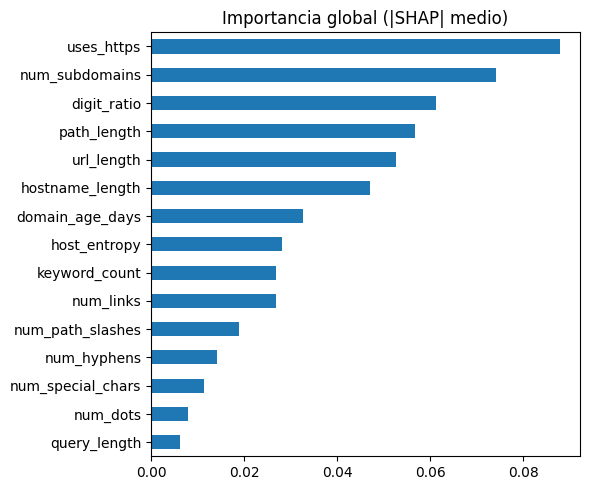

{
  "url": "https://www.wikipedia.org/",
  "final_url": "https://www.wikipedia.org/",
  "label": "phishing",
  "probability": 0.8897,
  "risk_level": "alto",
  "recommendation": "No ingresar credenciales ni datos personales en este sitio.",
  "factors": [
    {
      "feature": "num_subdomains",
      "value": 1.0,
      "shap": 0.3066
    },
    {
      "feature": "path_length",
      "value": 1.0,
      "shap": 0.2144
    },
    {
      "feature": "num_links",
      "value": 379.0,
      "shap": -0.1232
    }
  ],
  "missing_features": [],
  "model_version": "8c77d800f07a"
}
{
  "url": "(entrada inválida)",
  "final_url": "",
  "label": "error",
  "probability": null,
  "risk_level": "n/a",
  "recommendation": "URL no válida: solo se aceptan URLs http:// o https://",
  "factors": [],
  "missing_features": [],
  "model_version": "8c77d800f07a"
}
{
  "url": "http://ejemplo.com/login?id=***",
  "final_url": "http://ejemplo.com/login?id=***",
  "label": "phishing",
  "probability": 0.972

In [52]:
# Explicación global con el modelo evaluado en el 20 % apartado
expl_ho = Explainer(models_ho["stacking"].model, sel_ho.selected,
                    sel_ho.transform(X.iloc[tr]).sample(CFG["background_size"], random_state=SEED))
global_imp = expl_ho.global_importance(sel_ho.transform(X.iloc[te]), n=CFG["shap_global_rows"])
global_imp.to_csv(RES_DIR / "shap_global.csv", header=["mean_abs_shap"])
print(global_imp.round(4))
try:
    import matplotlib.pyplot as plt
    ax = global_imp.head(15)[::-1].plot.barh(figsize=(6, 5), title="Importancia global (|SHAP| medio)")
    plt.tight_layout(); plt.savefig(RES_DIR / "shap_global.png", dpi=200); plt.show()
except Exception as e:
    print("sin gráfico:", e)

# Agente completo, cargado desde los artefactos guardados en Drive
agent = PhishingAgent.from_artifacts(ART_DIR, use_whois=CFG["use_whois"])

for u in ["https://www.wikipedia.org/", "ftp://ejemplo.com", "http://ejemplo.com/login?id=1234"]:
    print(json.dumps(agent.analyze(u).to_dict(), indent=2, ensure_ascii=False))

## 9. Pruebas de evasión y medición (Evaluación)

Primera aproximación a la robustez, como describe la Metodología, se toman URLs de phishing del conjunto de prueba que el modelo detecta y se les aplican modificaciones sencillas. Se mide qué fracción **sigue detectándose**. Se usa el modelo entrenado solo con el 80 % (`models_ho`), no el modelo final, para no evaluar sobre datos vistos.

Las variantes que mantienen el sitio (subdominio extra, HTTPS, parámetros largos) conservan las características de HTML y WHOIS originales y recalculan las léxicas. Las que cambian el dominio (typosquatting, acortador *simulado*) dejan HTML y WHOIS como faltantes. El acortador es una simulación, no se crean enlaces acortados reales.

In [53]:
SUSTITUCIONES = {"o": "0", "l": "1", "i": "l", "e": "3", "a": "4", "s": "5"}

def _con_host(url, nuevo_host):
    p = urlparse(url)
    return urlunparse(p._replace(netloc=p.netloc.replace(p.hostname, nuevo_host, 1)))

def variantes_evasion(url, rng):
    p = urlparse(url)
    host = p.hostname
    reg = registered_domain(url)
    nombre, _, sufijo = reg.partition(".")
    for i, ch in enumerate(nombre):
        if ch in SUSTITUCIONES:
            nombre_typo = nombre[:i] + SUSTITUCIONES[ch] + nombre[i + 1:]
            break
    else:
        nombre_typo = nombre + nombre[-1:]
    relleno = "".join(rng.choices("abcdefghijklmnopqrstuvwxyz0123456789", k=40))
    corto = "".join(rng.choices("abcdefghijklmnopqrstuvwxyz0123456789", k=7))
    return {   # nombre: (URL modificada, ¿se conserva el sitio?)
        "subdominio_extra": (_con_host(url, "login.secure." + host), True),
        "https_forzado": (urlunparse(p._replace(scheme="https")), True),
        "parametros_largos": (url + ("&" if p.query else "?") + "ref=" + relleno, True),
        "typosquatting": (_con_host(url, host.replace(reg, nombre_typo + "." + sufijo)), False),
        "acortador_simulado": (f"https://bit.ly/{corto}", False),
    }

def evaluar_evasion(model, selector, test_df, seed=SEED, max_urls=500):
    rng = random.Random(seed)
    sel_cols = selector.selected
    base = test_df[test_df["label"] == 1]
    Xb = selector.transform(base[FEATURES])
    detectadas = base[model.predict_proba(Xb) >= 0.5].head(max_urls)
    print(f"phishing del conjunto de prueba detectado sin modificar: {len(detectadas)} de {len(base)}")
    filas = {}
    for _, row in detectadas.iterrows():
        for nombre, (nueva, mismo_sitio) in variantes_evasion(row["url"], rng).items():
            feats = row[FEATURES].to_dict()
            if not mismo_sitio:
                feats.update({c: SENTINEL for c in FeatureExtractor.domain_features + FeatureExtractor.html_features})
            feats.update(extractor.lexical(nueva))
            filas.setdefault(nombre, []).append(feats)
    out = []
    for nombre, lista in filas.items():
        Xv = selector.transform(pd.DataFrame(lista, columns=FEATURES))
        out.append(dict(variante=nombre, n=len(lista),
                        tasa_deteccion=float((model.predict_proba(Xv) >= 0.5).mean())))
    return pd.DataFrame(out).round(4)

test_df = model_df.iloc[te].reset_index(drop=True)
evasion = evaluar_evasion(models_ho["stacking"], sel_ho, test_df)
print(evasion)
evasion.to_csv(RES_DIR / "evasion.csv", index=False)

phishing del conjunto de prueba detectado sin modificar: 500 de 2019
             variante    n  tasa_deteccion
0    subdominio_extra  500           1.000
1       https_forzado  500           0.954
2   parametros_largos  500           0.996
3       typosquatting  500           0.992
4  acortador_simulado  500           0.904


### 9b. Tiempos por etapa y resumen para el paper

Los tiempos incluyen red y WHOIS reales, así que cambian entre sesiones: reporta siempre el entorno (`entorno.json`).

In [54]:
def tiempos_por_etapa(agent, urls, n=20):
    filas = []
    for u in urls[:n]:
        t0 = time.perf_counter(); page = agent.fetcher.fetch(u)
        t1 = time.perf_counter(); feats = agent.extractor.extract(u, page)
        xs = agent.selector.transform(pd.DataFrame([feats]))
        t2 = time.perf_counter(); agent.model.predict_proba(xs)
        t3 = time.perf_counter(); agent.explainer.explain(xs, 3)
        t4 = time.perf_counter()
        filas.append(dict(descarga_y_whois=t1 - t0, extraccion=t2 - t1, prediccion=t3 - t2, explicacion=t4 - t3))
    return pd.DataFrame(filas).describe().loc[["mean", "50%", "max"]].round(3)

muestra_urls = test_df["url"].sample(min(20, len(test_df)), random_state=SEED).tolist()
tiempos = tiempos_por_etapa(agent, muestra_urls)
print(tiempos)
tiempos.to_csv(RES_DIR / "tiempos.csv")

print("\n=== Resumen para el paper ===")
print("Entorno:", json.dumps(entorno))
print("\nCV (train):\n", cv_summary)
print("\nPrueba final:\n", holdout)
print("\nEvasión:\n", evasion)
print("\nFaltantes por clase:\n", faltantes)
print("\nArchivos en", RES_DIR)

ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out
ERROR:whois.whois:Error trying to connect to socket: closing socket - timed out


      descarga_y_whois  extraccion  prediccion  explicacion
mean             1.490       0.027       0.061        1.254
50%              0.660       0.004       0.062        1.193
max              6.789       0.152       0.078        1.619

=== Resumen para el paper ===
Entorno: {"python": "3.13.16", "scikit-learn": "1.6.1", "xgboost": "3.4.1", "lightgbm": "4.6.0", "shap": "0.54.1", "joblib": "1.6.0", "requests": "2.32.4", "beautifulsoup4": "4.13.5", "python-whois": "0.9.6", "tldextract": "5.4.0", "pandas": "2.2.3", "numpy": "2.1.3", "cpu": 2, "ram_gb": 13.6, "disco_libre_gb": 93.6}

CV (train):
                    n_features  accuracy  precision  recall      f1     fpr  \
model         k                                                              
random_forest 0.6          17    0.9058     0.9152  0.8944  0.9047  0.0829   
              0.7          20    0.9061     0.9157  0.8944  0.9049  0.0824   
              0.8          23    0.9074     0.9174  0.8953  0.9062  0.0807   
      

### 10. Gráficas

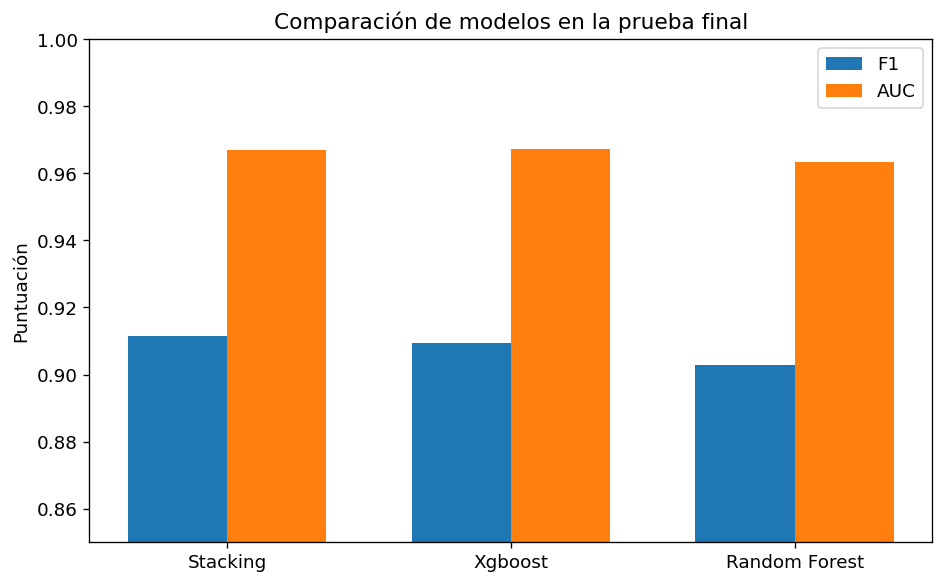

Guardada: /content/drive/MyDrive/phishing_agent/resultados/full/graficas/01_comparacion_modelos.png


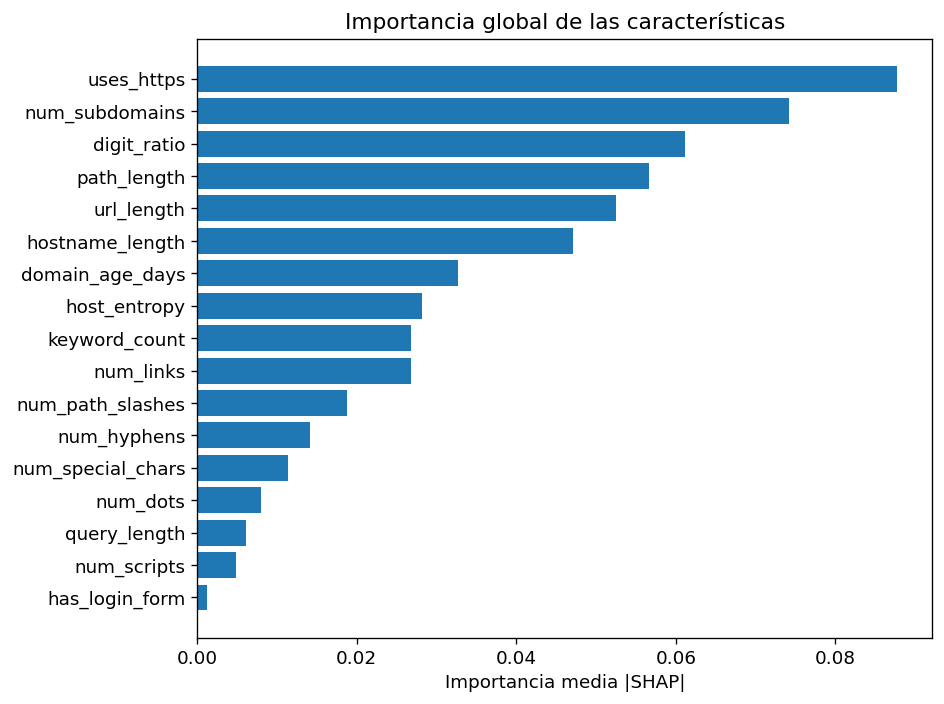

Guardada: /content/drive/MyDrive/phishing_agent/resultados/full/graficas/02_importancia_shap.png


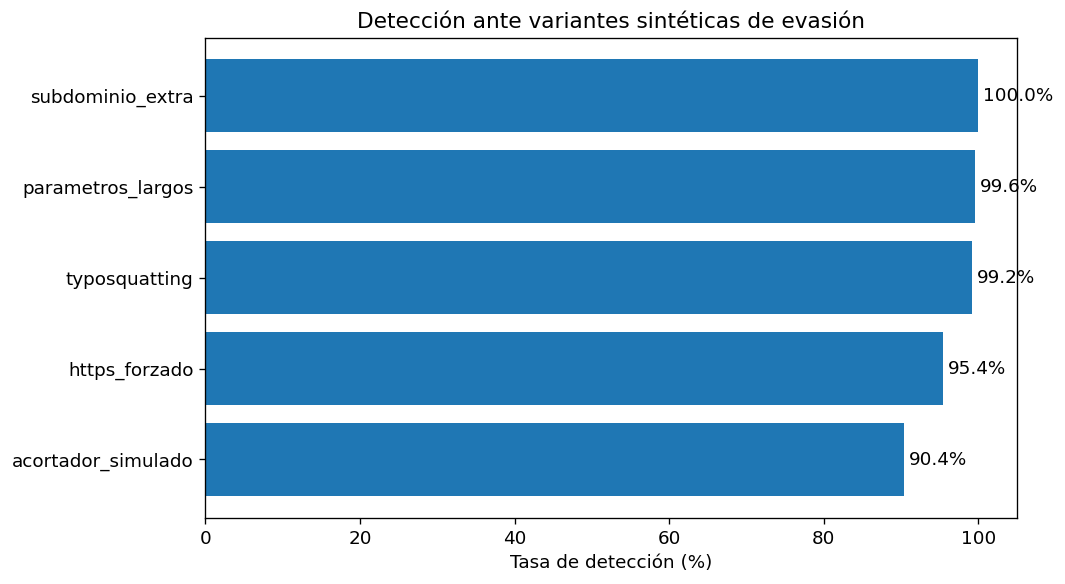

Guardada: /content/drive/MyDrive/phishing_agent/resultados/full/graficas/03_tasa_deteccion_evasion.png


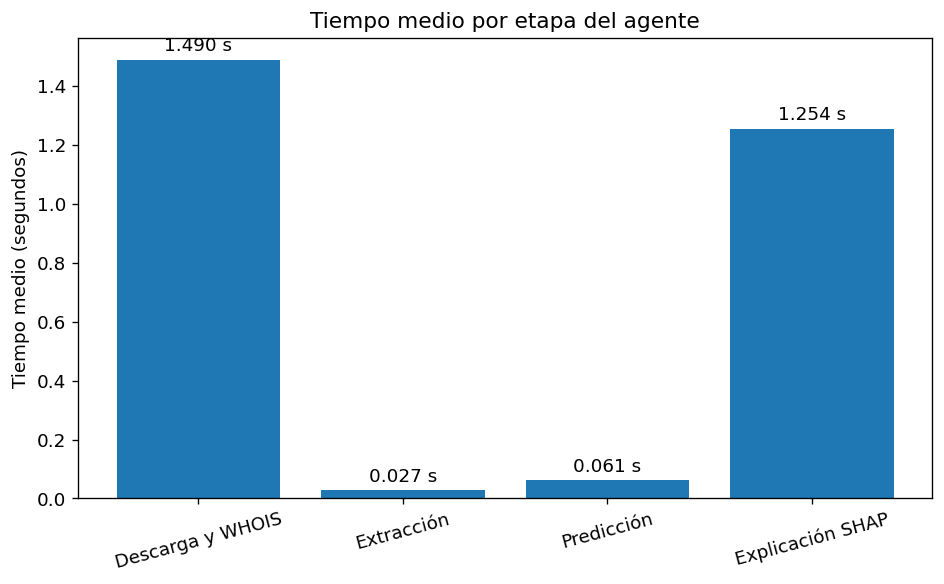

Guardada: /content/drive/MyDrive/phishing_agent/resultados/full/graficas/04_tiempos_por_etapa.png

Todas las gráficas están en: /content/drive/MyDrive/phishing_agent/resultados/full/graficas
Archivos PNG: 4


In [56]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shutil

RES_DIR = Path("/content/drive/MyDrive/phishing_agent/resultados/full")
FIG_DIR = RES_DIR / "graficas"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Estilo general para las figuras del paper
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "savefig.dpi": 300,
    "figure.dpi": 120,
})

def guardar_figura(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / nombre, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Guardada:", FIG_DIR / nombre)


# 1. Comparación de modelos: F1 y AUC en la prueba final
holdout = pd.read_csv(RES_DIR / "holdout.csv")
holdout = holdout.rename(columns={"Unnamed: 0": "model"})
holdout["model"] = holdout["model"].str.replace("_", " ").str.title()

metricas = ["f1", "auc"]
x = np.arange(len(holdout))
ancho = 0.35

fig, ax = plt.subplots()
ax.bar(x - ancho/2, holdout["f1"], ancho, label="F1")
ax.bar(x + ancho/2, holdout["auc"], ancho, label="AUC")
ax.set_xticks(x)
ax.set_xticklabels(holdout["model"])
ax.set_ylim(0.85, 1.0)
ax.set_ylabel("Puntuación")
ax.set_title("Comparación de modelos en la prueba final")
ax.legend()
guardar_figura("01_comparacion_modelos.png")


# 2. Importancia global SHAP
shap_csv = RES_DIR / "shap_global.csv"
shap_png = RES_DIR / "shap_global.png"

if shap_csv.exists():
    shap_df = pd.read_csv(shap_csv)
    # Admite CSV guardado con la característica como índice
    if len(shap_df.columns) >= 2:
        shap_df = shap_df.iloc[:, :2].copy()
        shap_df.columns = ["caracteristica", "importancia"]
    else:
        raise ValueError("El CSV SHAP no tiene las columnas esperadas.")

    shap_df = shap_df.sort_values("importancia", ascending=True).tail(17)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(shap_df["caracteristica"], shap_df["importancia"])
    ax.set_xlabel("Importancia media |SHAP|")
    ax.set_title("Importancia global de las características")
    guardar_figura("02_importancia_shap.png")
elif shap_png.exists():
    shutil.copy2(shap_png, FIG_DIR / "02_importancia_shap.png")
    print("Copiada gráfica SHAP existente.")
else:
    print("No se encontró el CSV ni la imagen SHAP.")


# 3. Tasa de detección ante variantes de evasión
evasion = pd.read_csv(RES_DIR / "evasion.csv")
evasion = evasion.sort_values("tasa_deteccion", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(evasion["variante"], evasion["tasa_deteccion"] * 100)
ax.set_xlim(0, 105)
ax.set_xlabel("Tasa de detección (%)")
ax.set_title("Detección ante variantes sintéticas de evasión")
ax.bar_label(barras, fmt="%.1f%%", padding=3)
guardar_figura("03_tasa_deteccion_evasion.png")


# 4. Tiempos por etapa
tiempos = pd.read_csv(RES_DIR / "tiempos.csv", index_col=0)
fila = tiempos.loc["mean"]
nombres = {
    "descarga_y_whois": "Descarga y WHOIS",
    "extraccion": "Extracción",
    "prediccion": "Predicción",
    "explicacion": "Explicación SHAP",
}
etiquetas = [nombres.get(c, c) for c in fila.index]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(etiquetas, fila.values)
ax.set_ylabel("Tiempo medio (segundos)")
ax.set_title("Tiempo medio por etapa del agente")
ax.tick_params(axis="x", rotation=15)
ax.bar_label(barras, fmt="%.3f s", padding=3)
guardar_figura("04_tiempos_por_etapa.png")


print("\nTodas las gráficas están en:", FIG_DIR)
print("Archivos PNG:", len(list(FIG_DIR.glob("*.png"))))
